# LightGBM + Feature Engineering (Default Risk)
ไฟล์นี้รันแยกได้เอง (ไม่ต้องรัน notebook เดิมก่อน) ขั้นตอน:
1. โหลดข้อมูล → 2. สร้าง feature ใหม่ → 3. ทำ CV แบบ out-of-fold เทียบ 3 แบบ (ก่อน FE / หลัง FE / หลัง FE + categorical)
→ 4. (เลือกได้) จูน Optuna → 5. เลือก threshold จาก OOF → 6. สร้างไฟล์ submission

ความต่างจาก notebook เดิม: ไม่ใช้ `StandardScaler`, ใช้ `StratifiedKFold` แทน `train_test_split` ครั้งเดียว,
ตั้ง `subsample_freq=1` ให้ `subsample` ทำงานจริง, ทำนาย test ด้วยค่าเฉลี่ยของโมเดลทุก fold

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score,
                             f1_score, roc_curve, precision_recall_curve)
from lightgbm import LGBMClassifier

TARGET = '12-Month Default Flag'
ID_COL = 'ID'

# ---- หน่วยของข้อมูล (ตามที่คุณระบุ) ----
# หมายเหตุ: ค่าคงที่เหล่านี้ไม่กระทบผลของ tree model (คูณทั้งคอลัมน์ด้วยเลขเท่ากัน อันดับข้อมูลไม่เปลี่ยน)
# ใส่ไว้เพื่อให้ตัวเลขอัตราส่วนอ่านง่าย/ตรงกับหน่วยจริง
INCOME_UNIT = 10_000   # Declared Annual Income x 10,000
RENT_UNIT   = 1_000    # Rent Burden x 1,000

# ---- วิธีเลือก threshold: 'balanced_acc' (Youden) หรือ 'f1' ----
THRESHOLD_METRIC = 'balanced_acc'

USE_OPTUNA = False     # เปลี่ยนเป็น True ถ้าต้องการจูนใหม่หลังได้ feature set แล้ว
N_TRIALS   = 50

In [2]:
train_path = "train_dataset.csv" if os.path.exists("train_dataset.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\train_dataset.csv"
test_path = "test_without_gt.csv" if os.path.exists("test_without_gt.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\test_without_gt.csv"
template_path = "submission_template_for_test.csv" if os.path.exists("submission_template_for_test.csv") else r"C:\Users\ice55\Downloads\Aihack Thailand 2026\submission_template_for_test.csv"

train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
template = pd.read_csv(template_path)

feature_cols = [
    'Application Channel', 'Gender', 'Marital Status', 'Age (in months)',
    'Residence Period (in months)', 'Occupation Category', 'Industry Category',
    'Employment Type Category', 'Insurance Type', 'Company Size Category',
    'Business Entity Type', 'Declared Annual Income', 'Payday',
    'Declared Number of Borrowings', 'Declared Borrowing Amount',
    'Desired Credit Limit', 'Residence Type', 'Rent Burden',
    'Residence Ownership Status', 'Number of Dependents',
    'Number of Dependent Children', 'Home Phone Number Available',
    'Mobile Phone Number Available', 'Employer Phone Number Available',
    'Driver Licence Number Available'
]
y = train_data[TARGET].values
print(train_data.shape, test_data.shape, 'default rate =', y.mean().round(4))

(68546, 27) (137091, 26) default rate = 0.0968


## 1) ตรวจค่าผิดปกติก่อนทำ ratio
ค่าอย่าง 0, -1, 9999 ในรายได้/ค่าเช่า/จำนวนครั้งที่กู้ อาจเป็นรหัส "ไม่มีข้อมูล" ซึ่งทำให้ ratio เพี้ยนได้

In [3]:
chk = ['Declared Annual Income', 'Rent Burden', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Number of Dependents',
       'Number of Dependent Children', 'Age (in months)', 'Residence Period (in months)']
display(train_data[chk].describe().T[['min', '25%', '50%', '75%', 'max']])
for c in chk:
    print(f"{c:35s} zero={(train_data[c] == 0).mean():.1%}  negative={(train_data[c] < 0).mean():.1%}")

,min,25%,50%,75%,max
Declared Annual Income,0.0,2200000.0,3000000.0,4000000.0,9.480000e+10
Rent Burden,0.0,0.0,10000.0,55000.0,7.000000e+08
Declared Number of Borrowings,0.0,0.0,1.0,2.0,9.000000e+00
Declared Borrowing Amount,0.0,0.0,300000.0,700000.0,1.236661e+10
Desired Credit Limit,10000.0,100000.0,200000.0,500000.0,8.000000e+06
Number of Dependents,0.0,0.0,0.0,1.0,2.000000e+01
Number of Dependent Children,0.0,0.0,0.0,0.0,9.000000e+00
Age (in months),234.0,282.0,368.0,530.0,8.400000e+02
Residence Period (in months),0.0,23.0,77.0,214.0,8.380000e+02


Declared Annual Income              zero=0.0%  negative=0.0%
Rent Burden                         zero=43.3%  negative=0.0%
Declared Number of Borrowings       zero=37.0%  negative=0.0%
Declared Borrowing Amount           zero=37.0%  negative=0.0%
Desired Credit Limit                zero=0.0%  negative=0.0%
Number of Dependents                zero=69.4%  negative=0.0%
Number of Dependent Children        zero=76.4%  negative=0.0%
Age (in months)                     zero=0.0%  negative=0.0%
Residence Period (in months)        zero=0.8%  negative=0.0%


## 2) Feature Engineering
ตัวหารที่เป็น 0 หรือ ติดลบ จะได้ค่า `NaN` (LightGBM จัดการ NaN ได้เอง) แทนที่จะเป็น inf

In [4]:
PHONE_COLS = ['Home Phone Number Available', 'Mobile Phone Number Available',
              'Employer Phone Number Available', 'Driver Licence Number Available']

def safe_div(a, b):
    a = pd.to_numeric(a, errors='coerce').astype(float)
    b = pd.to_numeric(b, errors='coerce').astype(float)
    return a / b.where(b > 0)          # ตัวหาร <= 0 หรือว่าง -> NaN

def add_features(df):
    d = df.copy()
    income_year  = d['Declared Annual Income'] * INCOME_UNIT
    income_month = income_year / 12
    rent_month   = d['Rent Burden'] * RENT_UNIT
    n_borrow     = d['Declared Number of Borrowings']
    borrowed     = d['Declared Borrowing Amount']
    n_dep        = d['Number of Dependents']

    # 1) ข้อมูลการติดต่อ
    d['Contact_Score'] = d[PHONE_COLS].sum(axis=1)

    # 2) พฤติกรรมการกู้
    d['Has_Debt']                = (n_borrow > 0).astype(int)
    d['Avg_Loan_Amount']         = safe_div(borrowed, n_borrow)                 # ยอดกู้เฉลี่ยต่อสัญญา
    d['New_Limit_vs_Existing']   = safe_div(d['Desired Credit Limit'], borrowed)  # วงเงินที่ขอ / หนี้เดิม
    d['Existing_DTI']            = safe_div(borrowed, income_year)              # หนี้เดิม / รายได้ต่อปี
    d['Desired_Limit_to_Income'] = safe_div(d['Desired Credit Limit'], income_year)  # ขอเกินตัวไหม

    # 3) ภาระค่าเช่า
    d['Rent_Ratio'] = safe_div(rent_month, income_month)

    # 4) ภาระครอบครัว / รายได้ต่อหัว
    d['Income_Per_Capita'] = income_month / (n_dep + 1)
    d['Child_Ratio']       = safe_div(d['Number of Dependent Children'], n_dep)
    d['Rent_Per_Capita']   = rent_month / (n_dep + 1)

    # 5) ความมั่นคง / เวลา
    d['Age_Years']           = d['Age (in months)'] / 12
    d['Residence_Age_Ratio'] = safe_div(d['Residence Period (in months)'], d['Age (in months)'])
    return d

NEW_FEATURES = ['Contact_Score', 'Has_Debt', 'Avg_Loan_Amount', 'New_Limit_vs_Existing', 'Existing_DTI',
                'Desired_Limit_to_Income', 'Rent_Ratio', 'Income_Per_Capita', 'Child_Ratio',
                'Rent_Per_Capita', 'Age_Years', 'Residence_Age_Ratio']

train_fe = add_features(train_data)
test_fe  = add_features(test_data)
display(train_fe[NEW_FEATURES].describe().T[['count', 'min', '50%', 'max']])
print('NaN ของ feature ใหม่ (%):')
print((train_fe[NEW_FEATURES].isna().mean() * 100).round(1).to_string())

,count,min,50%,max
Contact_Score,68546.0,1.000000e+00,3.000000e+00,4.000000e+00
Has_Debt,68546.0,0.000000e+00,1.000000e+00,1.000000e+00
Avg_Loan_Amount,43206.0,3.333333e+03,4.000000e+05,9.045030e+09
New_Limit_vs_Existing,43206.0,9.976057e-06,4.000000e-01,3.500000e+02
Existing_DTI,68536.0,0.000000e+00,9.433962e-06,3.864566e-01
Desired_Limit_to_Income,68536.0,1.225490e-10,7.894737e-06,1.300000e-02
Rent_Ratio,68536.0,0.000000e+00,3.834894e-03,3.600000e+02
Income_Per_Capita,68546.0,0.000000e+00,2.000000e+09,5.154167e+13
Child_Ratio,20957.0,0.000000e+00,6.666667e-01,1.000000e+00
Rent_Per_Capita,68546.0,0.000000e+00,6.250000e+06,7.000000e+11


NaN ของ feature ใหม่ (%):
Contact_Score               0.0
Has_Debt                    0.0
Avg_Loan_Amount            37.0
New_Limit_vs_Existing      37.0
Existing_DTI                0.0
Desired_Limit_to_Income     0.0
Rent_Ratio                  0.0
Income_Per_Capita           0.0
Child_Ratio                69.4
Rent_Per_Capita             0.0
Age_Years                   0.0
Residence_Age_Ratio         0.0


## 3) เตรียมชุด feature 3 แบบ
- **A** = 25 feature เดิม (numeric)
- **B** = A + feature ใหม่
- **C** = B โดยตั้งคอลัมน์รหัสหมวดหมู่เป็น `category` ให้ LightGBM จัดการเอง

แก้ `CAT_COLS` ได้ ถ้าคอลัมน์ไหนจริงๆ แล้วเรียงลำดับได้ (เช่น Company Size) ให้เอาออกจากลิสต์

In [5]:
CAT_COLS = ['Application Channel', 'Gender', 'Marital Status', 'Occupation Category',
            'Industry Category', 'Employment Type Category', 'Insurance Type',
            'Company Size Category', 'Business Entity Type', 'Residence Type',
            'Residence Ownership Status']

cat_levels = {c: sorted(pd.concat([train_data[c], test_data[c]]).dropna().unique()) for c in CAT_COLS}

def make_X(df, cols, as_category=False):
    X = df[cols].copy()
    if as_category:
        for c in CAT_COLS:
            if c in X.columns:
                X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

FEATURE_SETS = {
    'A_original':      dict(cols=feature_cols,                 cat=False),
    'B_plus_FE':       dict(cols=feature_cols + NEW_FEATURES,  cat=False),
    'C_plus_FE_categ': dict(cols=feature_cols + NEW_FEATURES,  cat=True),
}

## 4) ฟังก์ชัน CV แบบ out-of-fold + เลือก threshold

In [ ]:
BASE_PARAMS = dict(
    n_estimators=275, learning_rate=0.0189, max_depth=14, num_leaves=20,
    subsample=0.834, subsample_freq=1,       
    class_weight='balanced', n_jobs=-1, verbose=-1,
)

def run_cv(X, y, X_test=None, params=None, n_splits=5, seeds=(42,)):
    params = params or BASE_PARAMS
    oof = np.zeros(len(X))
    test_pred = None if X_test is None else np.zeros(len(X_test))
    for seed in seeds:
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for tr, va in skf.split(X, y):
            model = LGBMClassifier(**{**params, 'random_state': seed})
            model.fit(X.iloc[tr], y[tr])
            oof[va] += model.predict_proba(X.iloc[va])[:, 1] / len(seeds)
            if X_test is not None:
                test_pred += model.predict_proba(X_test)[:, 1] / (n_splits * len(seeds))
    return oof, test_pred

def best_threshold(y_true, prob, metric='balanced_acc'):
    if metric == 'f1':
        p, r, t = precision_recall_curve(y_true, prob)
        f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
        return float(t[np.argmax(f1)])
    fpr, tpr, t = roc_curve(y_true, prob)              # Youden's J = TPR - FPR (= balanced acc. สูงสุด)
    return float(t[np.argmax(tpr - fpr)])

def report(y_true, prob, metric=THRESHOLD_METRIC):
    thr = best_threshold(y_true, prob, metric)
    pred = (prob >= thr).astype(int)
    return dict(ROC_AUC=roc_auc_score(y_true, prob),
                PR_AUC=average_precision_score(y_true, prob),
                threshold=thr,
                balanced_acc=balanced_accuracy_score(y_true, pred),
                F1=f1_score(y_true, pred),
                positive_rate=pred.mean())

## 5) เทียบ A / B / C (CV 5 fold)

In [7]:
results, oofs = {}, {}
for name, cfg in FEATURE_SETS.items():
    X = make_X(train_fe, cfg['cols'], cfg['cat'])
    oofs[name], _ = run_cv(X, y)
    results[name] = report(y, oofs[name])
    print(name, 'AUC =', round(results[name]['ROC_AUC'], 4))

res_df = pd.DataFrame(results).T.round(4)
display(res_df)
BEST = res_df['ROC_AUC'].idxmax()
print('เลือกชุด feature:', BEST)

A_original AUC = 0.6468
B_plus_FE AUC = 0.6459
C_plus_FE_categ AUC = 0.6472


,ROC_AUC,PR_AUC,threshold,balanced_acc,F1,positive_rate
A_original,0.6468,0.1590,0.4912,0.6069,0.2291,0.4272
B_plus_FE,0.6459,0.1596,0.4811,0.6076,0.2282,0.4484
C_plus_FE_categ,0.6472,0.1605,0.4883,0.6086,0.2307,0.4208


เลือกชุด feature: C_plus_FE_categ


**วิธีอ่านผล:** ถ้า AUC ต่างกันน้อยกว่า ~0.002 ถือว่าอยู่ในระดับ noise ให้เลือกชุดที่เรียบง่ายกว่า
(A < B < C ในแง่ความซับซ้อน) ค่า `balanced_acc` คือค่าที่ใกล้เคียงกับคะแนน leaderboard ของคุณมากที่สุด

## 6) Feature importance ของชุดที่เลือก

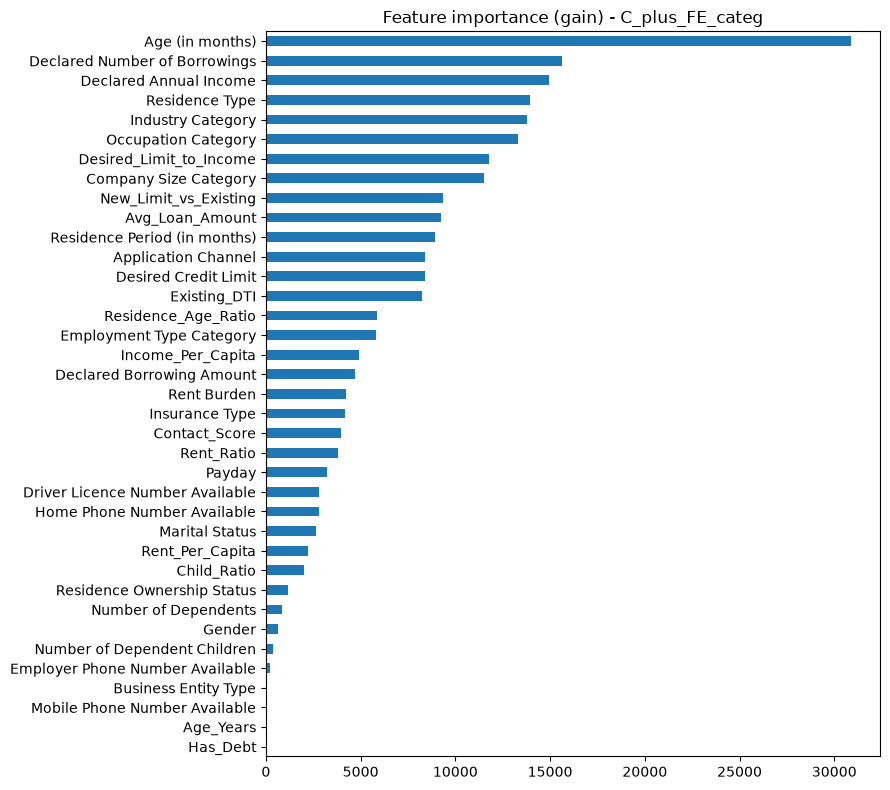

feature ใหม่ที่ importance ต่ำสุด 5 อันดับ (ลองตัดทิ้งได้):
Has_Debt              0.000000
Age_Years             0.000000
Child_Ratio        2010.262096
Rent_Per_Capita    2240.940508
Rent_Ratio         3793.640770


In [8]:
cfg = FEATURE_SETS[BEST]
X_all = make_X(train_fe, cfg['cols'], cfg['cat'])
m = LGBMClassifier(**{**BASE_PARAMS, 'importance_type': 'gain', 'random_state': 42}).fit(X_all, y)
imp = pd.Series(m.feature_importances_, index=cfg['cols']).sort_values()
imp.plot(kind='barh', figsize=(9, 8), title=f'Feature importance (gain) - {BEST}')
plt.tight_layout(); plt.show()
print('feature ใหม่ที่ importance ต่ำสุด 5 อันดับ (ลองตัดทิ้งได้):')
print(imp[imp.index.isin(NEW_FEATURES)].head(5).to_string())

## 7) (เลือกได้) จูน Optuna บนชุด feature ที่เลือก
ตั้ง `USE_OPTUNA = True` ด้านบน จะใช้เวลาประมาณหลายนาที ค่าที่ได้จะแทน `BASE_PARAMS` อัตโนมัติ

In [9]:
if USE_OPTUNA:
    import optuna
    from sklearn.model_selection import cross_val_score
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    cfg = FEATURE_SETS[BEST]
    X_all = make_X(train_fe, cfg['cols'], cfg['cat'])

    def objective(trial):
        params = dict(
            n_estimators=trial.suggest_int('n_estimators', 100, 600),
            learning_rate=trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
            max_depth=trial.suggest_int('max_depth', 4, 15),
            num_leaves=trial.suggest_int('num_leaves', 8, 40),
            min_child_samples=trial.suggest_int('min_child_samples', 20, 300),
            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            subsample_freq=1,
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.5, 1.0),
            reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
            class_weight='balanced', n_jobs=-1, verbose=-1, random_state=42,
        )
        cv = StratifiedKFold(5, shuffle=True, random_state=42)
        return cross_val_score(LGBMClassifier(**params), X_all, y, cv=cv, scoring='roc_auc').mean()

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    print('best CV AUC =', round(study.best_value, 4)); print(study.best_params)
    BASE_PARAMS = {**study.best_params, 'subsample_freq': 1, 'class_weight': 'balanced', 'n_jobs': -1, 'verbose': -1}
else:
    print('ข้าม Optuna (ใช้ BASE_PARAMS เดิม)')

ข้าม Optuna (ใช้ BASE_PARAMS เดิม)


## 8) สร้าง submission
- ทำ CV ซ้ำด้วย 3 seed → ได้ OOF ที่นิ่งขึ้น และทำนาย test เป็นค่าเฉลี่ยของ 15 โมเดล
- เลือก threshold จาก OOF (ให้ตรงกับ metric ที่ตั้งไว้) แล้วใช้กับ test
- ได้ 2 ไฟล์: แบบ 0/1 ตาม template และแบบความน่าจะเป็น (ใช้ได้ก็ต่อเมื่อการแข่งขันยอมรับค่าทศนิยม)

In [10]:
cfg = FEATURE_SETS[BEST]
X_all  = make_X(train_fe, cfg['cols'], cfg['cat'])
X_test = make_X(test_fe,  cfg['cols'], cfg['cat'])

oof, test_prob = run_cv(X_all, y, X_test, params=BASE_PARAMS, seeds=(42, 43, 44))
final = report(y, oof)
print({k: round(v, 4) for k, v in final.items()})
thr = final['threshold']

test_pred = (test_prob >= thr).astype(int)
sub = template[[ID_COL]].merge(
    pd.DataFrame({ID_COL: test_data[ID_COL].values, TARGET: test_pred, 'prob': test_prob}),
    on=ID_COL, how='left')
assert sub[TARGET].notna().all() and len(sub) == len(template), 'ID ไม่ตรงกับ template'

sub[[ID_COL, TARGET]].astype(int).to_csv('submission_lightGBM_fe_v6.csv', index=False)
sub[[ID_COL]].assign(**{TARGET: sub['prob']}).to_csv('submission_lightGBM_fe_v6_proba.csv', index=False)

print('threshold =', round(thr, 4), '| สัดส่วนทำนาย default ใน test =', round(test_pred.mean(), 4))
print('สัดส่วนทำนาย default ใน OOF =', round(final['positive_rate'], 4))
display(sub.head())

{'ROC_AUC': 0.65, 'PR_AUC': 0.1621, 'threshold': 0.4867, 'balanced_acc': 0.6117, 'F1': 0.2325, 'positive_rate': np.float64(0.4238)}
threshold = 0.4867 | สัดส่วนทำนาย default ใน test = 0.423
สัดส่วนทำนาย default ใน OOF = 0.4238


,ID,12-Month Default Flag,prob
0,211850001,0,0.276473
1,211850002,0,0.441248
2,211850003,0,0.400691
3,211870001,1,0.550209
4,211880001,1,0.635406
